# Рекомендации для музыкального сервиса

Загружаем библиотеки необходимые для выполнения кода ноутбука.

In [1]:
import gc
import os
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from catboost import CatBoostClassifier
from implicit.als import AlternatingLeastSquares
from scipy.sparse import csr_matrix

from dotenv import load_dotenv

from tqdm import tqdm

c:\Users\VivoBook 15X\p_env\python_env\miphi\Рекомендательные системы\Проект\env_recsys_start\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
work_dir = Path("recsys_work")
work_dir.mkdir(exist_ok=True)

## Этап 1. Первичная подготовка

Прочитаем данные, Проверим пропуски, дубликаты и типы данных. Списки ссылок на каталог проверим по сочетанию ID и типа сущности. Несуществующие ссылки удалим. Пустой список будет означать отсутствие сведений. Треки с неполными метаданными остаются в каталоге.

In [3]:
tracks = pd.read_parquet("tracks.parquet")
names = pd.read_parquet("catalog_names.parquet")
events = pd.read_parquet("interactions.parquet")

print("Треки", tracks.shape)
tracks.info()

print("\nНазвания из каталога", names.shape)
names.info()

print("\nПрослушивания", events.shape)
events.info()

Треки (1000000, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 4 columns):
 #   Column    Non-Null Count    Dtype 
---  ------    --------------    ----- 
 0   track_id  1000000 non-null  int64 
 1   albums    1000000 non-null  object
 2   artists   1000000 non-null  object
 3   genres    1000000 non-null  object
dtypes: int64(1), object(3)
memory usage: 30.5+ MB

Названия из каталога (1812471, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1812471 entries, 0 to 1812470
Data columns (total 3 columns):
 #   Column  Dtype 
---  ------  ----- 
 0   id      int64 
 1   type    object
 2   name    object
dtypes: int64(1), object(2)
memory usage: 41.5+ MB

Прослушивания (222629898, 4)
<class 'pandas.core.frame.DataFrame'>
Index: 222629898 entries, 0 to 291
Data columns (total 4 columns):
 #   Column      Dtype         
---  ------      -----         
 0   user_id     int32         
 1   track_id    int32         
 2   track_seq   i

У нас в данных 1 млн. треков и с округлением 223 млн. прослушиваний. Идентификаторы `user_id`, `track_id` уже имеют целочисленный тип. Преобразования типов не требуется.

In [4]:
tracks

,track_id,albums,artists,genres
0,26,"[3, 2490753]",[16],"[11, 21]"
1,38,"[3, 2490753]",[16],"[11, 21]"
2,135,"[12, 214, 2490809]",[84],[11]
3,136,"[12, 214, 2490809]",[84],[11]
4,138,"[12, 214, 322, 72275, 72292, 91199, 213505, 24...",[84],[11]
...,...,...,...,...
999995,101478482,[21399811],[5540395],"[3, 75]"
999996,101490148,[21403052],[9078726],"[11, 20]"
999997,101493057,[21403883],[11865715],"[44, 75]"
999998,101495927,[21404975],[4462686],"[3, 75]"


In [5]:
names

,id,type,name
0,3,album,Taller Children
1,12,album,Wild Young Hearts
2,13,album,Lonesome Crow
3,17,album,Graffiti Soul
4,26,album,Blues Six Pack
...,...,...,...
1812466,101478482,track,На лицо
1812467,101490148,track,Без капли мысли
1812468,101493057,track,SKITTLES
1812469,101495927,track,Москва


In [6]:
events

,user_id,track_id,track_seq,started_at
0,0,99262,1,2022-07-17
1,0,589498,2,2022-07-19
2,0,590262,3,2022-07-21
3,0,590303,4,2022-07-22
4,0,590692,5,2022-07-22
...,...,...,...,...
287,1374582,95514767,288,2022-12-29
288,1374582,97220301,289,2022-12-29
289,1374582,97241171,290,2022-12-29
290,1374582,98542641,291,2022-12-29


In [7]:
tracks.isna().sum()

track_id    0
albums      0
artists     0
genres      0
dtype: int64

In [8]:
names.isna().sum()

id      0
type    0
name    0
dtype: int64

In [9]:
events.isna().sum()

user_id       0
track_id      0
track_seq     0
started_at    0
dtype: int64

In [10]:
print("Пропуски дат:", events["started_at"].isna().sum())
print("Дубликаты ID трека:", tracks["track_id"].duplicated().sum())
print("Дубликаты ключа каталога:", names.duplicated(["type", "id"]).sum())
print("Дубли событий", events.duplicated().sum())

Пропуски дат: 0
Дубликаты ID трека: 0
Дубликаты ключа каталога: 0
Дубли событий 0


Дубликатов или пропусков в данных нет. Проверим возможные пробелы в заполнении таблицы.

In [11]:
print("Треки без альбомов", tracks["albums"].str.len().eq(0).sum())
print("Треки без исполнителей", tracks["artists"].str.len().eq(0).sum())
print("Треки без жанров", tracks["genres"].str.len().eq(0).sum())

print("Пустые названия в справочнике", names["name"].str.strip().eq("").sum())

Треки без альбомов 18
Треки без исполнителей 15369
Треки без жанров 3687
Пустые названия в справочнике 0


Теперь проверим, все ли ID из непустых списков есть в справочнике names. Например, у трека могут быть указаны два жанра, но один из их ID отсутствует среди записей с type == "genre".

In [12]:
for column, kind in [("albums", "album"), ("artists", "artist"), ("genres", "genre")]:
    catalog_ids = names.loc[names["type"] == kind, "id"]
    track_refs = tracks[column].explode().dropna()

    unknown_refs = track_refs[~track_refs.isin(catalog_ids)]
    print(f"{column} - ссылок без записи в справочнике: {len(unknown_refs)}")

albums - ссылок без записи в справочнике: 0
artists - ссылок без записи в справочнике: 0
genres - ссылок без записи в справочнике: 48369


У всех указанных альбомов и исполнителей есть записи в справочнике. А в списках genres нашлось 48 369 вхождений ID, для которых нет записи с type == "genre" в names. Для этих ID мы не можем подставить название жанра.

Удалим из списков genres только ID, которых нет в справочнике жанров. Так [12, 99] станет [12], если в справочнике есть только 12. Если у трека были только неизвестные жанры, получится []. Сам трек и его прослушивания остаются в данных.

In [13]:
valid_genre_ids = set(names.loc[names["type"] == "genre", "id"])

tracks["genres"] = tracks["genres"].apply(
    lambda genres: [genre_id for genre_id in genres if genre_id in valid_genre_ids]
)

print("Треки без жанров после очистки", tracks["genres"].str.len().eq(0).sum())

Треки без жанров после очистки 3694


Треки без жанров стоит оставить. Их прослушивания полезны для обучения ALS и подсчета популярности треков. В статистике по жанрам эти прослушивания останутся без категории.\
Чтобы понять, насколько это влияет на статистику, посчитаем долю прослушиваний треков без жанра.

In [14]:
tracks_without_genre = tracks.loc[tracks["genres"].str.len().eq(0), "track_id"]

plays_per_track = events["track_id"].value_counts()
plays_without_genre = plays_per_track.reindex(tracks_without_genre, fill_value=0).sum()

print(f"Прослушивания треков без жанра: {plays_without_genre / len(events):.2%}")

Прослушивания треков без жанра: 0.07%


**Вывод по первичному знакомству с данными**\
В tracks - 1 000 000 треков, в справочнике names - 1 812 471 записей, в events - 222 629 898 прослушиваний. Идентификаторы уже имеют целочисленный тип, а started_at хранится как дата и время. Преобразование типов не требуется.

Пропущенных значений в трех таблицах нет. В tracks нет повторов по track_id, а в names - по паре type и id. При этом у 18 треков пустой список альбомов, у 15 369 - исполнителей, у 3 687 - жанров.

По всем указанным альбомам и исполнителям найдены записи в справочнике. В списках жанров обнаружено 48 369 ссылок на ID, которых нет в справочнике жанров. Эти ID удалены из списков. После очистки на треки без известного жанра приходится 0,07% прослушиваний. Треки и их прослушивания сохранены для общей статистики и обучения модели рекомендаций.

## Этап 2. Анализ данных

Популярность измеряем количеством событий прослушивания. Если у трека несколько
жанров, его прослушивания учитываются в каждом из них. Для распределения
считаем и число событий, и число уникальных треков на пользователя.

Теперь перейдем к EDA. Сперва узнаем, сколько прослушиваний приходится на одного пользователя.

In [15]:
plays_per_user = events["user_id"].value_counts()

print(plays_per_user.describe(percentiles=[0.5, 0.9, 0.99]))

count    1.373221e+06
mean     1.621224e+02
std      3.512846e+02
min      1.000000e+00
50%      5.500000e+01
90%      3.890000e+02
99%      1.576000e+03
max      1.663700e+04
Name: count, dtype: float64


В данных 1 373 221 пользователь. За весь период у половины пользователей было 55 прослушиваний или меньше, а среднее - 162,1. Среднее заметно выше медианы, потому что у части пользователей прослушиваний гораздо больше.
- У 90% пользователей - 389 прослушиваний или меньше.
- У 99% - 1 576 или меньше.
- Максимум у одного пользователя - 16 637.

Каждая строка в events - одно прослушивание, поэтому если пользователь включил один трек пять раз, здесь это пять событий.

Построим гистограмму
Покажем диапазон до 99-го перцентиля, чтобы редкие очень большие значения не сжали основную часть графика. Все пользователи по-прежнему учитываются в describe().

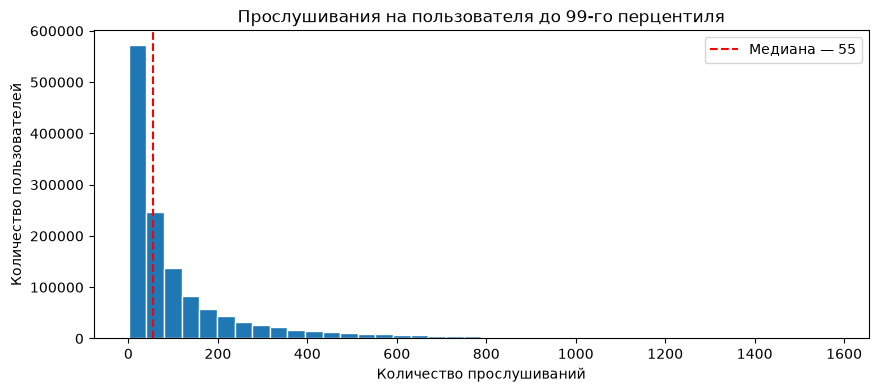

In [16]:
p99 = plays_per_user.quantile(0.99)

plt.figure(figsize=(10, 4))
plt.hist(plays_per_user, bins=40, range=(1, p99), edgecolor="white")
plt.axvline(plays_per_user.median(), color="red", linestyle="--", label="Медиана — 55")
plt.title("Прослушивания на пользователя до 99-го перцентиля")
plt.xlabel("Количество прослушиваний")
plt.ylabel("Количество пользователей")
plt.legend()
plt.show()

Распределение числа прослушиваний на пользователя скошено вправо. Медиана составляет 55 прослушиваний, среднее - 162,1. У 99% пользователей число прослушиваний не превышает 1 576, при этом максимальное значение достигает 16 637. Для описания активности типичного пользователя лучше использовать медиану, поскольку среднее чувствительно к высокой активности отдельных пользователей.

Найдем 10 самых прослушиваемых треков и выведем их названия. Используем plays_per_track, который уже посчитали для проверки жанров.

In [17]:
top_tracks = (
    plays_per_track.nlargest(10)
    .rename("plays")
    .rename_axis("track_id")
    .reset_index()
)

track_names = names.loc[names["type"] == "track"].set_index("id")["name"]
top_tracks["title"] = top_tracks["track_id"].map(track_names)

top_tracks[["track_id", "title", "plays"]]

,track_id,title,plays
0,53404,Smells Like Teen Spirit,111062
1,33311009,Believer,106921
2,178529,Numb,101924
3,35505245,I Got Love,99490
4,65851540,Юность,86670
5,24692821,Way Down We Go,86246
6,32947997,Shape of You,85886
7,51241318,In The End,85244
8,795836,Shape Of My Heart,85042
9,45499814,Life,84748


Посчитаем, какую долю всех прослушиваний собрал топ-10:

In [18]:
top_10_share = top_tracks["plays"].sum() / len(events)
print(f"Доля прослушиваний десяти самых популярных треков: {top_10_share:.2%}")

Доля прослушиваний десяти самых популярных треков: 0.42%


Самый прослушиваемый трек - Smells Like Teen Spirit (111 062 прослушивания). Десять лидеров собрали 933 233 прослушивания, или 0,42% всех событий.

Следующий шаг - топ-10 жанров.\
Если трек с двумя жанрами прослушали 100 раз, каждый жанр получит по 100 прослушиваний. Поэтому сумма по жанрам может превышать число событий в events. Для рейтинга жанров считаем именно так.

In [19]:
track_genres = tracks[["track_id", "genres"]].explode("genres")
track_genres = track_genres.dropna(subset=["genres"])
track_genres = track_genres.drop_duplicates(subset=["track_id", "genres"])

In [20]:
track_genres["plays"] = (
    track_genres["track_id"].map(plays_per_track).fillna(0).astype("int64")
)

In [21]:
top_genres = (
    track_genres.groupby("genres")["plays"].sum()
    .nlargest(10)
    .rename_axis("genre_id")
    .reset_index()
)

In [22]:
genre_names = names.loc[names["type"] == "genre"].set_index("id")["name"]
top_genres["genre"] = top_genres["genre_id"].map(genre_names)

In [23]:
top_genres[["genre_id", "genre", "plays"]]

,genre_id,genre,plays
0,11,pop,55578312
1,75,rap,37799821
2,102,allrock,31092013
3,20,ruspop,26626241
4,3,rusrap,25303695
5,68,electronics,20120981
6,16,dance,16291557
7,2,rusrock,13166147
8,14,rock,12772644
9,47,metal,12437375


Среди известных жанров лидирует pop - 55,6 млн прослушиваний. Следом идут rap (37,8 млн) и allrock (31,1 млн). Если у трека несколько жанров, его прослушивания учитываются в каждом из них, поэтому показатели разных жанров могут пересекаться.

Теперь посмотрим на треки без прослушиваний.\
plays_per_track уже содержит ID треков, которые прослушали хотя бы раз. Сравним их со всеми треками каталога:

In [24]:
unplayed_tracks = tracks.loc[
    ~tracks["track_id"].isin(plays_per_track.index),
    ["track_id"]
].copy()

unplayed_tracks["title"] = unplayed_tracks["track_id"].map(track_names)

print(f"Треков без прослушиваний: {len(unplayed_tracks):,}")
print(f"Доля каталога: {len(unplayed_tracks) / len(tracks):.2%}")

unplayed_tracks.head(10)

Треков без прослушиваний: 0
Доля каталога: 0.00%


,track_id,title


Каждый из 1 000 000 треков в каталоге прослушали хотя бы один раз за период, представленный в events. Доля треков без прослушиваний - 0%.

Сохраним items.parquet и events.parquet\
В items возьмем каталог с очищенными списками жанров и добавим названия треков из уже подготовленного track_names.

In [25]:
items = tracks.assign(title=tracks["track_id"].map(track_names))

items.to_parquet("items.parquet", index=False)
events.to_parquet("events.parquet", index=False)

Теперь сохраним данные в S3 бакете.

In [26]:
load_dotenv(".env")
bucket = os.environ["RECSYS_BUCKET"]

s3 = boto3.client(
    "s3",
    endpoint_url="https://storage.yandexcloud.net",
    region_name="ru-central1",
)

In [27]:
for filename in ["items.parquet", "events.parquet"]:
    key = f"recsys/data/{filename}"
    s3.upload_file(filename, bucket, key)
    print(f"Загружено: s3://{bucket}/{key}")

Загружено: s3://mle-20261122-8bad7bda58d7/recsys/data/items.parquet
Загружено: s3://mle-20261122-8bad7bda58d7/recsys/data/events.parquet


**Вывод к этапу 2**:\
Активность пользователей распределена неравномерно. Медиана составляет 55 прослушиваний на пользователя, среднее - 162,1. У 99% пользователей было не более 1 576 прослушиваний.

Самый прослушиваемый трек - Smells Like Teen Spirit со 111 062 прослушиваниями. На топ-10 треков пришлось 0,42% всех прослушиваний. Среди известных жанров лидируют pop, rap и allrock. Если у трека несколько жанров, его прослушивания учитываются в каждом из них.

За наблюдаемый период каждый из 1 млн треков каталога прослушали хотя бы раз. Подготовленный каталог и историю прослушиваний сохранили в items.parquet и events.parquet.

## Этап 3. Офлайн-рекомендации

Начнем с подготовки данных. Скачаем items.parquet и events.parquet из S3 и сразу разделим прослушивания по дате. События до 16 декабря 2022 года пойдут в обучение, а события с 16 декабря включительно - в тест.

In [28]:
load_dotenv(".env")
bucket = os.environ["RECSYS_BUCKET"]

s3 = boto3.client(
    "s3",
    endpoint_url="https://storage.yandexcloud.net",
    region_name="ru-central1",
)

data_dir = Path("offline_data")
data_dir.mkdir(exist_ok=True)

In [29]:
for filename in ["items.parquet", "events.parquet"]:
    s3.download_file(bucket, f"recsys/data/{filename}", str(data_dir / filename))

In [30]:
items = pd.read_parquet(data_dir / "items.parquet")

In [31]:
split_date = pd.Timestamp("2022-12-16")
events_path = data_dir / "events.parquet"

train = pd.read_parquet(
    events_path,
    filters=[("started_at", "<", split_date)],
)
test = pd.read_parquet(
    events_path,
    filters=[("started_at", ">=", split_date)],
)

In [32]:
print("Треков в каталоге", len(items))
print("Обучение", len(train), "событий до", train["started_at"].max())
print("Тест", len(test), "событий начиная с", test["started_at"].min())
print("Всего событий", len(train) + len(test))

Треков в каталоге 1000000
Обучение 208731252 событий до 2022-12-15 00:00:00
Тест 13898646 событий начиная с 2022-12-16 00:00:00
Всего событий 222629898


Возьмем 100 треков с наибольшим числом прослушиваний в train. \
Используем тот же критерий, что в EDA: каждое прослушивание считается отдельно. Топ строим по данным до 16 декабря, чтобы затем оценить его на будущих событиях из test.

In [33]:
train_plays_per_track = train["track_id"].value_counts()

In [34]:
top_popular = (
    train_plays_per_track.head(100)
    .rename("score")
    .rename_axis("track_id")
    .reset_index()
)
top_popular["rank"] = range(1, len(top_popular) + 1)
top_popular.head(10)

,track_id,score,rank
0,53404,110026,1
1,33311009,101076,2
2,178529,100866,3
3,35505245,95523,4
4,24692821,84153,5
5,795836,83749,6
6,6705392,80608,7
7,32947997,80243,8
8,37384,79512,9
9,45499814,78564,10


score - число прослушиваний в train, а rank = 1 - первое место. Этот список будет одинаковым для всех пользователей и послужит базой для сравнения с ALS.

Сохраним таблицу top_popular в parquet и загрузим файл в S3-бакет.

In [35]:
filename = "top_popular.parquet"
key = f"recsys/recommendations/{filename}"

top_popular.to_parquet(filename, index=False)
s3.upload_file(filename, bucket, key)

print(f"Загружено в s3://{bucket}/{key}")

Загружено в s3://mle-20261122-8bad7bda58d7/recsys/recommendations/top_popular.parquet


Создадим матрицу с пользователями и треками для ALS.

Строка матрицы - пользователь, столбец - трек. \
Если пользователь послушал трек три раза, на пересечении будет 3. \
Для пары без прослушиваний значение равно нулю. Формат CSR позволяет хранить такую матрицу без явного хранения всех нулей.

Сначала pd.factorize() присвоит пользователям и трекам последовательные номера с нуля. Исходные ID сохраним в user_ids и track_ids: они понадобятся, когда модель вернет номера строк и столбцов.

In [36]:
user_indices, user_ids = pd.factorize(train["user_id"], sort=True)
user_indices = user_indices.astype(np.int32)

In [37]:
track_indices, track_ids = pd.factorize(train["track_id"], sort=True)
track_indices = track_indices.astype(np.int32)

In [38]:
# Каждое событие добавляет единицу к паре пользователь - трек.
user_track_matrix = csr_matrix(
    (
        np.ones(len(train), dtype=np.float32),
        (user_indices, track_indices),
    ),
    shape=(len(user_ids), len(track_ids)),
)

del user_indices, track_indices

print("Размер матрицы", user_track_matrix.shape)
print(f"Пар с прослушиваниями: {user_track_matrix.nnz:}")

Размер матрицы (1342566, 999695)
Пар с прослушиваниями: 208731252


Обучаем ALS.\
Передаем в fit() матрицу, которую построили по train. ALS по числу прослушиваний каждой пары учится представлять пользователей и треки в виде векторов.

In [39]:
als_model = AlternatingLeastSquares(
    factors=32,
    iterations=10,
    regularization=0.05,
    num_threads=4,
    random_state=42,
    use_gpu=False,
)

als_model.fit(user_track_matrix, show_progress=True)

print("Векторы пользователей", als_model.user_factors.shape)
print("Векторы треков", als_model.item_factors.shape)

c:\Users\VivoBook 15X\p_env\python_env\miphi\Рекомендательные системы\Проект\env_recsys_start\Lib\site-packages\implicit\cpu\als.py:95: RuntimeWarning: OpenBLAS is configured to use 20 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()
100%|██████████| 10/10 [03:46<00:00, 22.69s/it]


Векторы пользователей (1342566, 32)
Векторы треков (999695, 32)


Получим персональные рекомендации ALS.\
Берем обученную als_model и сохраняем по 50 треков на пользователя. Позже эти 50 треков станут кандидатами для ранжирования. Поскольку у нас 1,34 млн пользователей, то считаем рекомендации порциями и сразу записываем их в parquet.

Ранее прослушанные треки оставляем среди кандидатов: в музыкальном сервисе повторное прослушивание тоже может быть уместной рекомендацией.

In [40]:
filename = "personal_als.parquet"
batch_size = 256
n_candidates = 50

original_user_ids = np.asarray(user_ids)
original_track_ids = np.asarray(track_ids)

schema = pa.schema([
    ("user_id", pa.int32()),
    ("track_id", pa.int32()),
    ("als_score", pa.float32()),
    ("rank", pa.int32()),
])

with pq.ParquetWriter(filename, schema) as writer:
    for start in tqdm(range(0, len(user_ids), batch_size), desc="Рекомендации ALS"):
        stop = min(start + batch_size, len(user_ids))
        batch_user_indices = np.arange(start, stop)

        recommended_indices, scores = als_model.recommend(
            batch_user_indices,
            user_track_matrix[batch_user_indices],
            N=n_candidates,
            filter_already_liked_items=False,
        )

        batch = pa.Table.from_pydict({
            "user_id": np.repeat(original_user_ids[batch_user_indices], n_candidates),
            "track_id": original_track_ids[recommended_indices.ravel()],
            "als_score": scores.ravel(),
            "rank": np.tile(np.arange(1, n_candidates + 1), stop - start),
        }, schema=schema)

        writer.write_table(batch)

Рекомендации ALS: 100%|██████████| 5245/5245 [1:05:08<00:00,  1.34it/s]


Проверим число строк и загрузим файл в S3.

In [41]:
rows = pq.ParquetFile(filename).metadata.num_rows
assert rows == len(user_ids) * n_candidates

In [42]:
key = f"recsys/recommendations/{filename}"
s3.upload_file(filename, bucket, key)

print(f"Загружено {rows:} строк в s3://{bucket}/{key}")

Загружено 67128300 строк в s3://mle-20261122-8bad7bda58d7/recsys/recommendations/personal_als.parquet


Найдем похожие треки через ALS.\
Для каждого трека из train найдем до 10 похожих треков. Используем ту же обученную als_model. Метод similar_items() сравнивает векторы треков, которые модель выучила на прослушиваниях.\
Запросим по 11 результатов, потому что в выдачу может попасть сам исходный трек. Уберем его и оставим первые 10. Как и на предыдущем шаге, считаем порциями и сразу записываем в parquet.

In [43]:
similar_filename = "similar.parquet"
n_similar = 10
batch_size = 256

original_track_ids = np.asarray(track_ids)

similar_schema = pa.schema([
    ("track_id", pa.int32()),
    ("similar_track_id", pa.int32()),
    ("score", pa.float32()),
    ("rank", pa.int32()),
])

with pq.ParquetWriter(similar_filename, similar_schema) as writer:
    for start in tqdm(range(0, len(track_ids), batch_size), desc="Похожие треки"):
        stop = min(start + batch_size, len(track_ids))
        batch_track_indices = np.arange(start, stop)

        similar_indices, scores = als_model.similar_items(
            batch_track_indices,
            N=min(n_similar + 1, len(track_ids)),
        )

        # Убираем исходный трек из его собственной выдачи.
        valid = (similar_indices >= 0) & (
            similar_indices != batch_track_indices[:, None]
        )
        ranks = valid.cumsum(axis=1)
        rows, cols = np.where(valid & (ranks <= n_similar))

        batch = pa.Table.from_pydict({
            "track_id": original_track_ids[batch_track_indices[rows]],
            "similar_track_id": original_track_ids[similar_indices[rows, cols]],
            "score": scores[rows, cols],
            "rank": ranks[rows, cols],
        }, schema=similar_schema)

        writer.write_table(batch)

Похожие треки: 100%|██████████| 3906/3906 [1:07:34<00:00,  1.04s/it]


In [44]:
rows = pq.ParquetFile(similar_filename).metadata.num_rows
key = f"recsys/recommendations/{similar_filename}"

s3.upload_file(similar_filename, bucket, key)
print(f"Загружено {rows:} строк в s3://{bucket}/{key}")

Загружено 9996950 строк в s3://mle-20261122-8bad7bda58d7/recsys/recommendations/similar.parquet


Подготовим целевую переменную для ранжировщика.\
Разделим train еще раз. Выберем 9 декабря как границу, чтобы оставить последнюю неделю обучения для разметки.

Для разметки возьмем до 20 000 пользователей, которые слушали музыку с 9 по 15 декабря. Так на следующем шаге не придется снова считать персональные рекомендации для всех 1,34 млн пользователей.

In [45]:
ranker_split_date = pd.Timestamp("2022-12-09")
ranker_history_mask = train["started_at"] < ranker_split_date

label_events = train.loc[~ranker_history_mask, ["user_id", "track_id"]]

In [46]:
label_users = label_events["user_id"].drop_duplicates()
ranker_user_ids = label_users.sample(
    n=min(20_000, len(label_users)),
    random_state=42,
)

In [47]:
ranker_labels = (
    label_events.loc[label_events["user_id"].isin(ranker_user_ids)]
    .drop_duplicates(subset=["user_id", "track_id"])
    .assign(target=1)
)

print(f"Прослушиваний до 9 декабря: {ranker_history_mask.sum():,}")
print(f"Пользователей для разметки: {len(ranker_user_ids):,}")
print(f"Положительных пар: {len(ranker_labels):,}")

ranker_labels.head()

Прослушиваний до 9 декабря: 200,834,917
Пользователей для разметки: 20,000
Положительных пар: 212,515


,user_id,track_id,target
674,12,31219146,1
14529,86,79692191,1
14530,86,79692218,1
14531,86,79692219,1
14532,86,79736591,1


Если пользователь слушал один трек несколько раз за эту неделю, в ranker_labels все равно будет одна пара с target=1. На следующем шаге получим кандидатов по истории до 9 декабря, присоединим эту разметку и поставим target=0 кандидатам, которых пользователь за неделю не послушал. Ранее сохраненный файл personal_als.parquet пригодится для итогового ранжирования.

Собираем обучающую таблицу для ранжировщика.\
Получим до 50 кандидатов на пользователя от ALS, обученной на прослушиваниях до 9 декабря. Затем посмотрим, какие из этих треков пользователь действительно послушал с 9 по 15 декабря. В итоге каждая строка будет содержать пару user_id, track_id, три признака и target.

Обучаем ALS на ранней истории.

In [48]:
ranker_history = train.loc[ranker_history_mask, ["user_id", "track_id"]]
ranker_track_plays = ranker_history["track_id"].value_counts()

In [49]:
user_idx, early_user_ids = pd.factorize(ranker_history["user_id"], sort=True)
user_idx = user_idx.astype(np.int32)

track_idx, early_track_ids = pd.factorize(ranker_history["track_id"], sort=True)
track_idx = track_idx.astype(np.int32)

In [50]:
ranker_matrix = csr_matrix(
    (np.ones(len(ranker_history), dtype=np.float32), (user_idx, track_idx)),
    shape=(len(early_user_ids), len(early_track_ids)),
)
del ranker_history, user_idx, track_idx

ranker_als = AlternatingLeastSquares(
    factors=32,
    iterations=10,
    regularization=0.05,
    num_threads=4,
    random_state=42,
    use_gpu=False,
)
ranker_als.fit(ranker_matrix, show_progress=True)

100%|██████████| 10/10 [07:33<00:00, 45.34s/it]


Получаем кандидатов для выбранных пользователей.\
Считаем рекомендации только для пользователей из ranker_user_ids, у которых уже была история до 9 декабря.

In [51]:
selected_indices = pd.Index(early_user_ids).get_indexer(ranker_user_ids)
selected_indices = selected_indices[selected_indices >= 0]

In [52]:
early_user_ids = np.asarray(early_user_ids)
early_track_ids = np.asarray(early_track_ids)
n_ranker_candidates = min(50, len(early_track_ids))
candidate_batches = []

In [53]:
for start in tqdm(range(0, len(selected_indices), 256), desc="Кандидаты для обучения"):
    batch_users = selected_indices[start:start + 256]

    recommended_indices, scores = ranker_als.recommend(
        batch_users,
        ranker_matrix[batch_users],
        N=n_ranker_candidates,
        filter_already_liked_items=False,
    )

    candidate_batches.append(pd.DataFrame({
        "user_id": np.repeat(early_user_ids[batch_users], n_ranker_candidates),
        "track_id": early_track_ids[recommended_indices.ravel()],
        "als_score": scores.ravel(),
    }))

Кандидаты для обучения: 100%|██████████| 76/76 [01:10<00:00,  1.08it/s]


In [54]:
train_candidates = pd.concat(candidate_batches, ignore_index=True)
del candidate_batches, ranker_matrix, ranker_als

print(f"Пользователей с ранней историей: {len(selected_indices):,}")

Пользователей с ранней историей: 19,424


Добавляем признаки и target.\
Три признака: als_score, число прослушиваний трека до 9 декабря и число его известных жанров.

In [55]:
genre_counts = items.set_index("track_id")["genres"].str.len()

train_candidates["track_plays"] = (
    train_candidates["track_id"].map(ranker_track_plays).fillna(0).astype("int32")
)
train_candidates["genre_count"] = (
    train_candidates["track_id"].map(genre_counts).fillna(0).astype("int32")
)

In [56]:
ranker_train = train_candidates.merge(
    ranker_labels,
    on=["user_id", "track_id"],
    how="left",
)
ranker_train["target"] = ranker_train["target"].fillna(0).astype("int8")

print(ranker_train["target"].value_counts())

target
0    965623
1      5577
Name: count, dtype: int64


In [57]:
ranker_train.head()

,user_id,track_id,als_score,track_plays,genre_count,target
0,380288,84382282,0.256438,38933,2,0
1,380288,83063895,0.243513,45564,2,0
2,380288,78824202,0.225116,33606,1,0
3,380288,85192958,0.208812,22521,2,0
4,380288,38275100,0.200369,53258,1,0


target=1 означает, что пользователь послушал кандидата в неделю разметки.\
target=0 означает, что такого прослушивания в эту неделю не было.

Обучаем CatBoost для ранжирования.\
Возьмем из ranker_train три признака: оценку ALS, число прослушиваний трека до 9 декабря и число известных жанров. CatBoost обучится предсказывать target для каждой пары пользователь и трек. Затем будем сортировать кандидатов каждого пользователя по вероятности target=1.

In [58]:
ranker_features = ["als_score", "track_plays", "genre_count"]

X_ranker_train = ranker_train[ranker_features]
y_ranker_train = ranker_train["target"]

assert y_ranker_train.nunique() == 2, "Для обучения нужны оба класса: 0 и 1"

In [59]:
ranker = CatBoostClassifier(
    iterations=100,
    depth=5,
    loss_function="Logloss",
    random_seed=42,
    thread_count=4,
    verbose=20,
)

ranker.fit(X_ranker_train, y_ranker_train)

Learning rate set to 0.5
0:	learn: 0.3220298	total: 257ms	remaining: 25.5s
20:	learn: 0.0344028	total: 2.23s	remaining: 8.39s
40:	learn: 0.0340684	total: 4.2s	remaining: 6.04s
60:	learn: 0.0338174	total: 6.22s	remaining: 3.98s
80:	learn: 0.0336612	total: 8.24s	remaining: 1.93s
99:	learn: 0.0335458	total: 10.2s	remaining: 0us


Качество самих рекомендаций проверим позже на test, то есть на прослушиваниях с 16 декабря. \
Следующим шагом применим ranker к уже готовому personal_als.parquet и сохраним новый порядок треков в recommendations.parquet.

Переранжируем рекомендации ALS и сохраним результат.\
Возьмем personal_als.parquet и пересчитаем порядок 50 кандидатов каждого пользователя по оценке CatBoost. На вход подаем те же три признака, что при обучении. Теперь track_plays берем из train_plays_per_track - это число прослушиваний по всей истории до 16 декабря, которая была бы доступна на момент выдачи рекомендаций.

In [60]:
als_file = pq.ParquetFile("personal_als.parquet")
output_filename = "recommendations.parquet"

output_schema = pa.schema([
    ("user_id", pa.int32()),
    ("track_id", pa.int32()),
    ("score", pa.float32()),
    ("rank", pa.int32()),
])

with pq.ParquetWriter(output_filename, output_schema) as writer:
    for group_idx in tqdm(range(als_file.num_row_groups), desc="Ранжирование CatBoost"):
        batch = als_file.read_row_group(group_idx).to_pandas()

        batch["track_plays"] = (
            batch["track_id"].map(train_plays_per_track).fillna(0).astype("int32")
        )
        batch["genre_count"] = (
            batch["track_id"].map(genre_counts).fillna(0).astype("int32")
        )

        batch["score"] = ranker.predict_proba(
            batch[ranker_features], thread_count=4
        )[:, 1].astype("float32")

        batch = batch.sort_values(
            ["user_id", "score", "rank"],
            ascending=[True, False, True],
        )
        batch["rank"] = (batch.groupby("user_id").cumcount() + 1).astype("int32")

        table = pa.Table.from_pandas(
            batch[["user_id", "track_id", "score", "rank"]],
            schema=output_schema,
            preserve_index=False,
        )
        writer.write_table(table)

Ранжирование CatBoost: 100%|██████████| 5245/5245 [03:38<00:00, 23.99it/s]


In [61]:
rows = pq.ParquetFile(output_filename).metadata.num_rows
assert rows == als_file.metadata.num_rows

key = f"recsys/recommendations/{output_filename}"
s3.upload_file(output_filename, bucket, key)

print(f"Загружено {rows:} строк в s3://{bucket}/{key}")

Загружено 67128300 строк в s3://mle-20261122-8bad7bda58d7/recsys/recommendations/recommendations.parquet


**Вывод-заключение к этапу 3:**\
На прослушиваниях до 16 декабря 2022 года построены топ популярных треков, персональные рекомендации ALS и списки похожих треков. Для каждого пользователя CatBoost переранжировал 50 кандидатов ALS с учетом оценки ALS, числа прослушиваний трека и числа его известных жанров.

Результаты сохранены в top_popular.parquet, personal_als.parquet, similar.parquet и recommendations.parquet.

## Этап 4. Оценка качества

Сравним первые 10 рекомендаций каждого метода с тем, что пользователи действительно слушали с 16 декабря.\
Для всех трех методов возьмем одних и тех же пользователей: тех, кто есть в test и у кого была история в train. Повторные прослушивания одного трека в test считаем одним релевантным треком.\
Считаем следующие метрики:
- Precision@10\
Сколько из 10 рекомендаций пользователь послушал. Делим число попаданий на 10 и усредняем по пользователям.
- Recall@10\
Какую долю своих тестовых треков пользователь получил в рекомендациях. Считаем долю для каждого пользователя и усредняем.
- Coverage@10\
Какая доля каталога появилась хотя бы в одном топ-10.
- Novelty@10\
Насколько редки рекомендованные треки. Используем log2 доли прослушиваний трека в train и усредняем по всем рекомендациям.

Подготовим тестовые пары и популярность треков.


In [62]:
k = 10

test_pairs = test.loc[
    test["user_id"].isin(user_ids),
    ["user_id", "track_id"],
].drop_duplicates()

# Сколько разных треков каждый пользователь послушал в тесте
relevant_count = test_pairs.groupby("user_id").size()
n_eval_users = len(relevant_count)
catalog_size = len(items)

# По этому индексу будем проверять, есть ли пара в тесте
test_index = pd.MultiIndex.from_frame(test_pairs)

track_novelty = -np.log2(train_plays_per_track / len(train))

print(f"Пользователей в оценке: {n_eval_users:,}")
print(f"Тестовых пар пользователь - трек: {len(test_pairs):,}")

Пользователей в оценке: 752,870
Тестовых пар пользователь - трек: 12,796,287


Посчитаем метрики топа популярных.\
У всех пользователей один и тот же топ-10, поэтому достаточно найти, у кого эти треки встречались в тесте.

In [63]:
popular = pd.read_parquet("top_popular.parquet")
top_ids = popular.nsmallest(k, "rank")["track_id"]

popular_hits = test_pairs.loc[test_pairs["track_id"].isin(top_ids)]
hits_per_user = popular_hits["user_id"].value_counts()
hits_per_user = hits_per_user.reindex(relevant_count.index, fill_value=0)

popular_metrics = {
    "model": "Топ популярных",
    "precision@10": (hits_per_user / k).mean(),
    "recall@10": (hits_per_user / relevant_count).mean(),
    "coverage@10": top_ids.nunique() / catalog_size,
    "novelty@10": top_ids.map(track_novelty).mean(),
}

Посчитаем метрики ALS и CatBoost порциями.\
В обоих файлах уже есть rank. Читаем только нужные столбцы и оставляем строки с rank <= 10.

In [64]:
def evaluate_personal(filename, model_name):
    total_hits = 0
    recall_sum = 0.0
    novelty_sum = 0.0
    n_recommendations = 0
    recommended_tracks = set()

    source = pq.ParquetFile(filename)
    batches = source.iter_batches(
        batch_size=200_000,
        columns=["user_id", "track_id", "rank"],
    )

    for batch in tqdm(batches, desc=model_name):
        recs = batch.to_pandas()
        recs = recs.loc[
            recs["rank"].le(k) & recs["user_id"].isin(relevant_count.index)
        ]

        rec_pairs = pd.MultiIndex.from_frame(recs[["user_id", "track_id"]])
        is_hit = test_index.get_indexer(rec_pairs) >= 0
        hit_users = recs.loc[is_hit, "user_id"]

        total_hits += len(hit_users)
        recall_sum += (1 / hit_users.map(relevant_count)).sum()
        novelty_sum += recs["track_id"].map(track_novelty).sum()
        n_recommendations += len(recs)
        recommended_tracks.update(recs["track_id"].unique())

    return {
        "model": model_name,
        "precision@10": total_hits / (n_eval_users * k),
        "recall@10": recall_sum / n_eval_users,
        "coverage@10": len(recommended_tracks) / catalog_size,
        "novelty@10": novelty_sum / n_recommendations,
    }

In [65]:
metrics = pd.DataFrame([
    popular_metrics,
    evaluate_personal("personal_als.parquet", "ALS"),
    evaluate_personal("recommendations.parquet", "ALS + CatBoost"),
]).set_index("model")

metrics.round(6)

ALS: 336it [00:08, 40.30it/s]
ALS + CatBoost: 336it [00:06, 52.60it/s]


,precision@10,recall@10,coverage@10,novelty@10
model,,,,
Топ популярных,0.002727,0.002684,0.000010,11.198681
ALS,0.007706,0.011824,0.002192,12.178185
ALS + CatBoost,0.009668,0.012743,0.004437,12.519386


**Вывод**:\
На тестовых прослушиваниях с 16 декабря 2022 года ALS превзошел топ популярных треков по всем четырем метрикам. ALS + CatBoost показал лучшие результаты. По сравнению с ALS без переранжирования Precision@10 вырос с 0,77% до 0,97% (+25,5% относительно ALS), а Recall@10 — с 1,18% до 1,27% (+7,8%).

Покрытие каталога выросло примерно вдвое, с 0,22% до 0,44%. Novelty@10 увеличилась с 12,18 до 12,52, то есть в топ-10 в среднем стали попадать менее популярные треки. Таким образом, на этой тестовой выборке переранжирование одновременно увеличило число попаданий и расширило набор рекомендуемых треков. При этом абсолютное число попаданий остаётся небольшим - в среднем 0,097 на список из 10 рекомендаций.